In [59]:
#creating the custom dataset
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

np.random.seed(42)

data = {
    "Study_Hours": np.random.randint(1, 10, 1000),
    "Attendance": np.random.randint(50, 101, 1000),
    "Previous_Marks": np.random.randint(30, 101, 1000),
    "Assignment_Score": np.random.randint(20, 101, 1000),
    "Sleep_Hours": np.random.randint(4, 10, 1000)
}

df = pd.DataFrame(data)

df["Final_Marks"] = (
    df["Study_Hours"] * 3 +
    df["Attendance"] * 0.2 +
    df["Previous_Marks"] * 0.3 +
    df["Assignment_Score"] * 0.2 +
    df["Sleep_Hours"] * 1.5 +
    np.random.normal(0, 5, 1000)
)

df["Final_Marks"] = df["Final_Marks"].clip(0, 100)

In [60]:
print(df.info())
print("---------")
print(df.head())
print("---------")
print(df.tail())
print("---------")
print(df.shape)
print("---------")
print(df.describe())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Study_Hours       1000 non-null   int64  
 1   Attendance        1000 non-null   int64  
 2   Previous_Marks    1000 non-null   int64  
 3   Assignment_Score  1000 non-null   int64  
 4   Sleep_Hours       1000 non-null   int64  
 5   Final_Marks       1000 non-null   float64
dtypes: float64(1), int64(5)
memory usage: 47.0 KB
None
---------
   Study_Hours  Attendance  Previous_Marks  Assignment_Score  Sleep_Hours  \
0            7          73              99                51            4   
1            4          72              57                86            6   
2            8          57              55                86            9   
3            5          96              54                47            9   
4            7          86              41                63        

In [61]:
print(df.isnull().sum())
print("---------")
print(df.duplicated().sum())
print("---------")
print(df.dtypes)
print("---------")
print(df.describe())

Study_Hours         0
Attendance          0
Previous_Marks      0
Assignment_Score    0
Sleep_Hours         0
Final_Marks         0
dtype: int64
---------
0
---------
Study_Hours           int64
Attendance            int64
Previous_Marks        int64
Assignment_Score      int64
Sleep_Hours           int64
Final_Marks         float64
dtype: object
---------
       Study_Hours   Attendance  Previous_Marks  Assignment_Score  \
count  1000.000000  1000.000000     1000.000000       1000.000000   
mean      4.898000    75.304000       63.848000         60.403000   
std       2.603916    14.622976       20.252137         22.805233   
min       1.000000    50.000000       30.000000         20.000000   
25%       3.000000    63.000000       47.000000         41.000000   
50%       5.000000    75.000000       63.500000         61.000000   
75%       7.000000    88.000000       81.000000         80.000000   
max       9.000000   100.000000      100.000000        100.000000   

       Sleep_Hours 

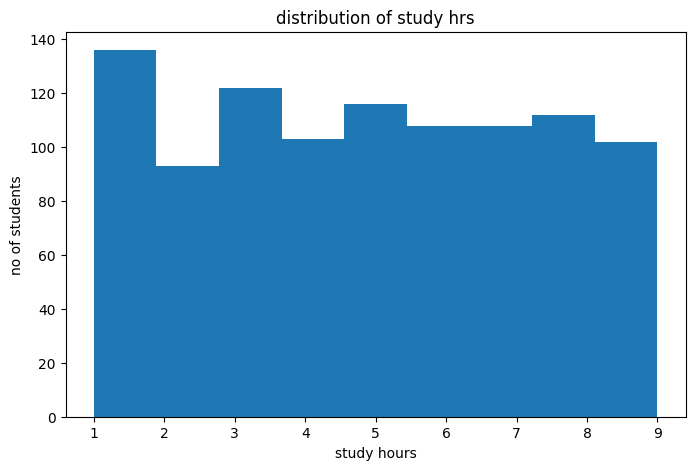

In [62]:
plt.figure(figsize=(8,5))
plt.hist(df["Study_Hours"],bins=9)
plt.xlabel("study hours")
plt.ylabel("no of students")
plt.title("distribution of study hrs")
plt.show()

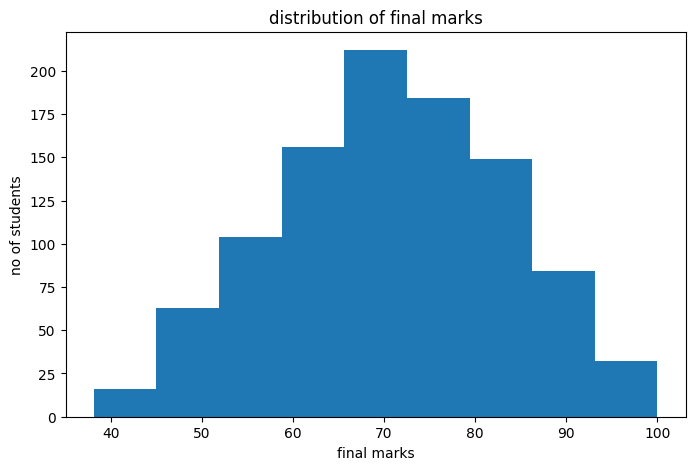

In [63]:
plt.figure(figsize=(8,5))
plt.hist(df["Final_Marks"],bins=9)
plt.xlabel("final marks")
plt.ylabel("no of students")
plt.title("distribution of final marks")
plt.show()

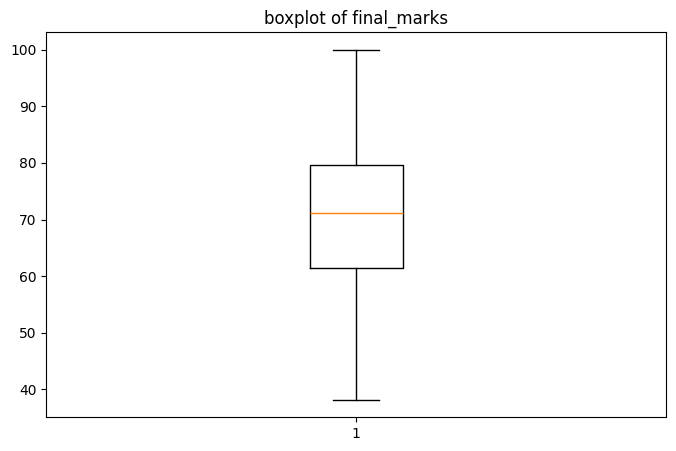

In [64]:
plt.figure(figsize=(8,5))
plt.boxplot(x=df["Final_Marks"])
plt.title("boxplot of final_marks")
plt.show()

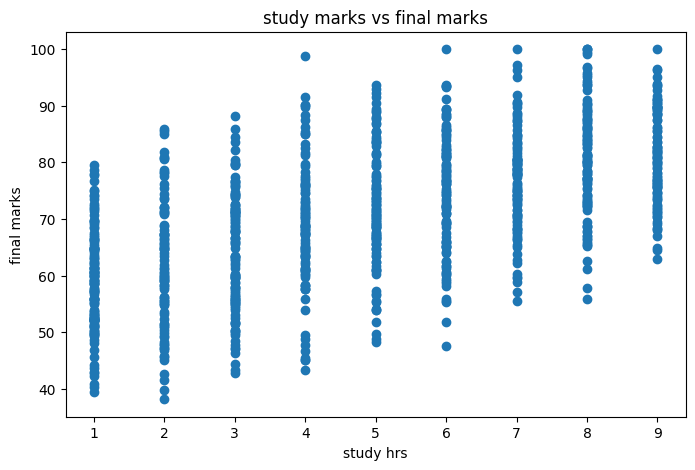

In [65]:
plt.figure(figsize=(8,5))
plt.scatter(x=df["Study_Hours"],y=df["Final_Marks"])
plt.xlabel("study hrs")
plt.ylabel("final marks")
plt.title("study marks vs final marks")
plt.show()

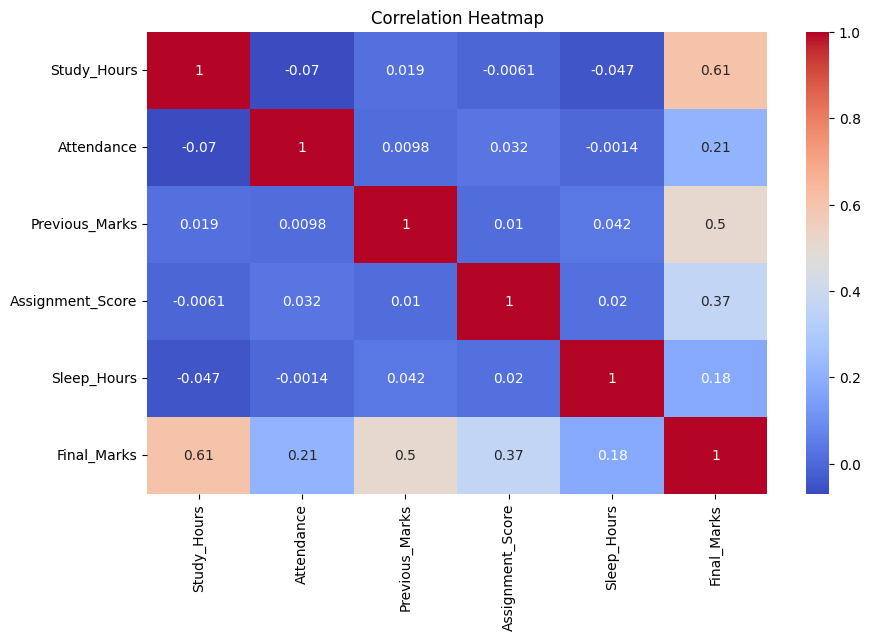

In [66]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [67]:
df.isnull().sum()
df.drop_duplicates(inplace=True)

In [68]:
Q1 = df["Final_Marks"].quantile(0.25)

Q3 = df["Final_Marks"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower)
print("Upper Bound:", upper)

Q1: 61.472772448074195
Q3: 79.71172843962334
IQR: 18.238955991549147
Lower Bound: 34.114338460750474
Upper Bound: 107.07016242694706


In [69]:
outliers = df[
    (df["Final_Marks"] < lower) |
    (df["Final_Marks"] > upper)
]

print(outliers)
print("Number of outliers:", len(outliers))

Empty DataFrame
Columns: [Study_Hours, Attendance, Previous_Marks, Assignment_Score, Sleep_Hours, Final_Marks]
Index: []
Number of outliers: 0


In [70]:
X=df.iloc[:,:-1]
y=df.iloc[:,-1]

In [71]:
print(X.shape)
print(y.shape)

(1000, 5)
(1000,)


In [72]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [73]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(X_train,y_train)
print("training accuracy:",lr.score(X_train,y_train))
print("intercept:",lr.intercept_)
print("cofffiecient:",lr.coef_)

training accuracy: 0.8318056482326913
intercept: -0.24402272110899048
cofffiecient: [3.05182216 0.21339165 0.29864345 0.19846051 1.34584216]


In [74]:
y_test_pred = lr.predict(X_test)

testing_data = X_test.copy()

testing_data["Actual"] = y_test
testing_data["Predicted"] = y_test_pred
testing_data


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Sleep_Hours,Actual,Predicted
521,5,60,46,52,6,65.571590,59.951185
737,9,98,59,68,9,85.538831,91.362616
740,6,80,91,74,6,86.681792,85.075927
660,8,87,54,79,8,82.777165,85.307492
411,3,100,42,43,5,55.818496,58.056647
...,...,...,...,...,...,...,...
408,2,94,76,36,6,49.152757,63.834970
332,1,69,63,79,9,67.529828,64.137320
208,4,75,81,92,9,85.038099,82.528705
613,2,67,100,70,7,84.962655,73.334338


In [75]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
mae=mean_absolute_error(y_test,y_test_pred)
mse=mean_squared_error(y_test,y_test_pred)
rmse=np.sqrt(mse)
print(mae)
print(mse)
print(rmse)
print(r2_score(y_test,y_test_pred))

3.799872798698956
23.414840827777407
4.838888387613152
0.8394197853999038


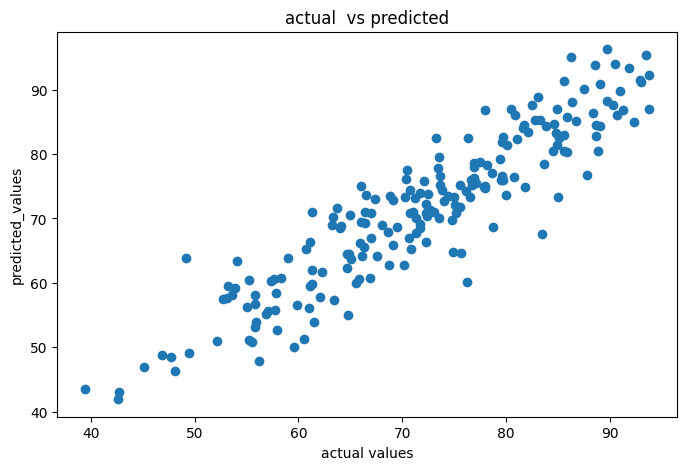

In [76]:
plt.figure(figsize=(8,5))
plt.scatter(y_test,y_test_pred)
plt.xlabel("actual values")
plt.ylabel("predicted_values")
plt.title("actual  vs predicted")
plt.show()

In [77]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original training shape:", X_train.shape)
print("Polynomial training shape:", X_train_poly.shape)

print("Original testing shape:", X_test.shape)
print("Polynomial testing shape:", X_test_poly.shape)
from sklearn.linear_model import LinearRegression

poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train)

print("Polynomial Regression model trained!")
y_poly_pred = poly_model.predict(X_test_poly)

print(y_poly_pred[:10])
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

# Polynomial Regression metrics
poly_mae = mean_absolute_error(y_test, y_poly_pred)

poly_mse = mean_squared_error(y_test, y_poly_pred)

poly_rmse = np.sqrt(poly_mse)

poly_r2 = r2_score(y_test, y_poly_pred)

print("Polynomial MAE:", poly_mae)
print("Polynomial MSE:", poly_mse)
print("Polynomial RMSE:", poly_rmse)
print("Polynomial R2:", poly_r2)
comparison = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Polynomial Regression"
    ],
    "MAE": [mae, poly_mae],
    "MSE": [mse, poly_mse],
    "RMSE": [rmse, poly_rmse],

})

print(comparison)

Original training shape: (800, 5)
Polynomial training shape: (800, 21)
Original testing shape: (200, 5)
Polynomial testing shape: (200, 21)
Polynomial Regression model trained!
[59.90214535 92.58825935 84.87864149 86.04917987 57.64519176 60.55997114
 85.51399278 96.05351523 82.49150743 87.50327465]
Polynomial MAE: 3.831411594778613
Polynomial MSE: 23.480329567133595
Polynomial RMSE: 4.845650582443352
Polynomial R2: 0.8389706601678745
                        Model       MAE        MSE      RMSE
0  Multiple Linear Regression  3.799873  23.414841  4.838888
1       Polynomial Regression  3.831412  23.480330  4.845651


In [78]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Multiple Linear Regression predictions
y_pred = lr.predict(X_test)

# Polynomial Regression predictions
y_poly_pred = poly_model.predict(X_test_poly)

comparison = pd.DataFrame({
    "Model": ["Multiple Linear Regression", "Polynomial Regression"],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, y_poly_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, y_poly_pred))
    ],
    "R2": [
        r2_score(y_test, y_pred),
        r2_score(y_test, y_poly_pred)
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Multiple Linear Regression,3.799873,4.838888,0.839420
1,Polynomial Regression,3.831412,4.845651,0.838971


In [79]:
import joblib

joblib.dump(poly_model, "polynomial_model.pkl")
joblib.dump(poly, "polynomial_features.pkl")

['polynomial_features.pkl']

In [80]:
df["Results"]=np.where(df["Final_Marks"]>=40,"pass","fail")
print(df["Results"].value_counts())

Results
pass    997
fail      3
Name: count, dtype: int64


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Study_Hours       1000 non-null   int64  
 1   Attendance        1000 non-null   int64  
 2   Previous_Marks    1000 non-null   int64  
 3   Assignment_Score  1000 non-null   int64  
 4   Sleep_Hours       1000 non-null   int64  
 5   Final_Marks       1000 non-null   float64
 6   Results           1000 non-null   object 
dtypes: float64(1), int64(5), object(1)
memory usage: 54.8+ KB


In [82]:
X=df[["Study_Hours","Attendance","Sleep_Hours","Assignment_Score","Previous_Marks"]]
y=df["Results"]
print(X.shape)
print(y.shape)

(1000, 5)
(1000,)


***Classiification***

In [83]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 5)
(200, 5)
(800,)
(200,)


In [84]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(X_train,y_train)
y_train_pred=lr.predict(X_test)

In [85]:
print("actual_values")
print(y_test.head(10).to_list())
print("predicted_results")
print(y_train_pred[:10])

actual_values
['pass', 'pass', 'pass', 'pass', 'pass', 'pass', 'pass', 'pass', 'pass', 'pass']
predicted_results
['pass' 'pass' 'pass' 'pass' 'pass' 'pass' 'pass' 'pass' 'pass' 'pass']


In [86]:
y_pred = lr.predict(X_test)

from sklearn.metrics import accuracy_score
print("Test accuracy:", accuracy_score(y_test, y_pred))

Test accuracy: 0.995


In [87]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred, labels=["fail", "pass"]))

[[  0   1]
 [  0 199]]


In [88]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred,labels=["fail","pass"],zero_division=0))


              precision    recall  f1-score   support

        fail       0.00      0.00      0.00         1
        pass       0.99      1.00      1.00       199

    accuracy                           0.99       200
   macro avg       0.50      0.50      0.50       200
weighted avg       0.99      0.99      0.99       200



In [89]:
df["Results"]=np.where(df["Final_Marks"]>=70,"pass","fail")
print(df["Results"].value_counts())

Results
pass    536
fail    464
Name: count, dtype: int64


In [90]:
X = df[["Study_Hours", "Attendance", "Sleep_Hours",
        "Assignment_Score", "Previous_Marks"]]

y = df["Results"]
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("Training labels:\n", y_train.value_counts())
print("Testing labels:\n", y_test.value_counts())

Training labels:
 Results
pass    417
fail    383
Name: count, dtype: int64
Testing labels:
 Results
pass    119
fail     81
Name: count, dtype: int64


In [92]:

from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

In [93]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test,y_pred,labels=["fail","pass"]))

[[ 68  13]
 [ 13 106]]


In [94]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred,labels=("pass","fail")))

              precision    recall  f1-score   support

        pass       0.89      0.89      0.89       119
        fail       0.84      0.84      0.84        81

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



In [95]:

from sklearn.tree import DecisionTreeClassifier
tree_model=DecisionTreeClassifier(random_state=42,max_depth=3)
tree_model.fit(X_train,y_train)
tree_pred=tree_model.predict(X_test)
from sklearn.metrics import classification_report,confusion_matrix
print("confusion matrix")
print(confusion_matrix(y_test,tree_pred,labels=["fail","pass"]))
print("\n classification report")
print(classification_report(y_test,tree_pred,labels=["fail","pass"]))

confusion matrix
[[ 58  23]
 [ 13 106]]

 classification report
              precision    recall  f1-score   support

        fail       0.82      0.72      0.76        81
        pass       0.82      0.89      0.85       119

    accuracy                           0.82       200
   macro avg       0.82      0.80      0.81       200
weighted avg       0.82      0.82      0.82       200



In [96]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier()
rf.fit(X_train,y_train)
random_forest_pred=rf.predict(X_test)
from sklearn.metrics import confusion_matrix,classification_report
print("confusion matrix:",confusion_matrix(y_test,random_forest_pred,labels=["fail","pass"]))
print("traning accuracy",rf.score(X_train,y_train))
print("testing accuracy",rf.score(X_test,y_test))
print("classification report",classification_report(y_test,random_forest_pred))

confusion matrix: [[67 14]
 [20 99]]
traning accuracy 1.0
testing accuracy 0.83
classification report               precision    recall  f1-score   support

        fail       0.77      0.83      0.80        81
        pass       0.88      0.83      0.85       119

    accuracy                           0.83       200
   macro avg       0.82      0.83      0.83       200
weighted avg       0.83      0.83      0.83       200



In [98]:
n_est = [100, 102, 104, 106]

for i in n_est:
    rf1 = RandomForestClassifier(
        n_estimators=i, criterion="gini", random_state=42
    )
    rf1.fit(X_train, y_train)
    pred1 = rf1.predict(X_test)

    print("Confusion matrix:", confusion_matrix(y_test, pred1, labels=["fail", "pass"]))
    print("Training accuracy:", rf1.score(X_train, y_train))
    print("Testing accuracy:", rf1.score(X_test, y_test))
    print("Classification report:", classification_report(y_test, pred1, labels=["fail", "pass"]))
    print("-" * 50)

for i in n_est:
    rf2 = RandomForestClassifier(
        n_estimators=i, criterion="entropy", random_state=42
    )
    rf2.fit(X_train, y_train)
    pred2 = rf2.predict(X_test)

    print("Confusion matrix:", confusion_matrix(y_test, pred2, labels=["fail", "pass"]))
    print("Training accuracy:", rf2.score(X_train, y_train))
    print("Testing accuracy:", rf2.score(X_test, y_test))
    print("Classification report:", classification_report(y_test, pred2, labels=["fail", "pass"]))
    print("-" * 50)

Confusion matrix: [[ 69  12]
 [ 18 101]]
Training accuracy: 1.0
Testing accuracy: 0.85
Classification report:               precision    recall  f1-score   support

        fail       0.79      0.85      0.82        81
        pass       0.89      0.85      0.87       119

    accuracy                           0.85       200
   macro avg       0.84      0.85      0.85       200
weighted avg       0.85      0.85      0.85       200

--------------------------------------------------
Confusion matrix: [[ 69  12]
 [ 18 101]]
Training accuracy: 1.0
Testing accuracy: 0.85
Classification report:               precision    recall  f1-score   support

        fail       0.79      0.85      0.82        81
        pass       0.89      0.85      0.87       119

    accuracy                           0.85       200
   macro avg       0.84      0.85      0.85       200
weighted avg       0.85      0.85      0.85       200

--------------------------------------------------
Confusion matrix: [[ 69 

In [99]:
print("Trees:", i, "| Criterion:", "gini", "| Test accuracy:", rf1.score(X_test, y_test),
      "| Fail recall:", classification_report(
          y_test, pred1, labels=["fail", "pass"], output_dict=True
      )["fail"]["recall"])

Trees: 106 | Criterion: gini | Test accuracy: 0.85 | Fail recall: 0.8641975308641975


In [107]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()
knn.fit(X_train,y_train)
knn_pred=knn.predict(X_test)
from sklearn.metrics import confusion_matrix,classification_report
print("training accuracy:",knn.score(X_train,y_train))
print("testing accuracy:",knn.score(X_test,y_test))
print("confusion_matrix:",confusion_matrix(y_test,knn_pred))
print("confusion_matrix:",classification_report(y_test,knn_pred,labels=["fail","pass"]))

training accuracy: 0.81875
testing accuracy: 0.785
confusion_matrix: [[61 20]
 [23 96]]
confusion_matrix:               precision    recall  f1-score   support

        fail       0.73      0.75      0.74        81
        pass       0.83      0.81      0.82       119

    accuracy                           0.79       200
   macro avg       0.78      0.78      0.78       200
weighted avg       0.79      0.79      0.79       200



In [111]:
for i in range(5,11):
  from sklearn.neighbors import KNeighborsClassifier
  knn1=KNeighborsClassifier(n_neighbors=i)
  knn1.fit(X_train,y_train)
  knn_pred1=knn1.predict(X_test)
  from sklearn.metrics import confusion_matrix,classification_report
  print("training accuracy:",knn1.score(X_train,y_train))
  print("testing accuracy:",knn1.score(X_test,y_test))
  print("confusion_matrix:",confusion_matrix(y_test,knn_pred1))
  print("confusion_matrix:",classification_report(y_test,knn_pred1,labels=["fail","pass"]))
  print("-----------------------------------------------------------------------------------------")

training accuracy: 0.81875
testing accuracy: 0.785
confusion_matrix: [[61 20]
 [23 96]]
confusion_matrix:               precision    recall  f1-score   support

        fail       0.73      0.75      0.74        81
        pass       0.83      0.81      0.82       119

    accuracy                           0.79       200
   macro avg       0.78      0.78      0.78       200
weighted avg       0.79      0.79      0.79       200

-----------------------------------------------------------------------------------------
training accuracy: 0.8025
testing accuracy: 0.76
confusion_matrix: [[64 17]
 [31 88]]
confusion_matrix:               precision    recall  f1-score   support

        fail       0.67      0.79      0.73        81
        pass       0.84      0.74      0.79       119

    accuracy                           0.76       200
   macro avg       0.76      0.76      0.76       200
weighted avg       0.77      0.76      0.76       200

----------------------------------------------

In [112]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report

knn_scaled = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=8)
)

knn_scaled.fit(X_train, y_train)
scaled_pred = knn_scaled.predict(X_test)

print("Test accuracy:", knn_scaled.score(X_test, y_test))
print(classification_report(y_test, scaled_pred, labels=["fail", "pass"]))

Test accuracy: 0.825
              precision    recall  f1-score   support

        fail       0.76      0.84      0.80        81
        pass       0.88      0.82      0.85       119

    accuracy                           0.82       200
   macro avg       0.82      0.83      0.82       200
weighted avg       0.83      0.82      0.83       200



In [114]:
from sklearn.naive_bayes import GaussianNB
nb=GaussianNB()
nb.fit(X_train,y_train)
nb_pred=nb.predict(X_test)
print("test accuracy:",accuracy_score(y_test,nb_pred))
print(classification_report(y_test,nb_pred,labels=["fail","pass"]))

test accuracy: 0.89
              precision    recall  f1-score   support

        fail       0.86      0.86      0.86        81
        pass       0.91      0.91      0.91       119

    accuracy                           0.89       200
   macro avg       0.89      0.89      0.89       200
weighted avg       0.89      0.89      0.89       200



In [121]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report,accuracy_score
for i in [1e-9,1e-8,1e-7,1e-6,1e-5]:
  nb=GaussianNB(var_smoothing=i)
  nb.fit(X_train,y_train)
  pred=nb.predict(X_test)
  report=classification_report(y_test,pred,labels=["fail","pass"],output_dict=True)
  print(
        "var_smoothing:", i,
        "| Test accuracy:", accuracy_score(y_test, pred),
        "| Fail recall:", report["fail"]["recall"]
    )


var_smoothing: 1e-09 | Test accuracy: 0.89 | Fail recall: 0.8641975308641975
var_smoothing: 1e-08 | Test accuracy: 0.89 | Fail recall: 0.8641975308641975
var_smoothing: 1e-07 | Test accuracy: 0.89 | Fail recall: 0.8641975308641975
var_smoothing: 1e-06 | Test accuracy: 0.89 | Fail recall: 0.8641975308641975
var_smoothing: 1e-05 | Test accuracy: 0.89 | Fail recall: 0.8641975308641975


In [124]:
# Use the same feature order as X_train
new_student = [[5, 90, 75, 80, 8]]

prediction = nb.predict(new_student)
print("Predicted result:", prediction[0])

Predicted result: pass


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(
